<a href="https://colab.research.google.com/github/gt-varma/Comparative-Analysis-of-Machine-Learning-Algorithms-for-Text-Classification-Using-TF-IDF/blob/main/Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

All libraries imported successfully!

========== DATASET INFORMATION ==========
Dataset name: 20 Newsgroups
Total documents: 3732
Number of classes: 4
Classes: ['comp.graphics', 'rec.sport.baseball', 'sci.med', 'talk.politics.misc']

Class distribution:
comp.graphics : 973
rec.sport.baseball : 994
sci.med : 990
talk.politics.misc : 775

CLASS DISTRIBUTION TABLE
          Category  Number of Documents
     comp.graphics                  973
rec.sport.baseball                  994
           sci.med                  990
talk.politics.misc                  775


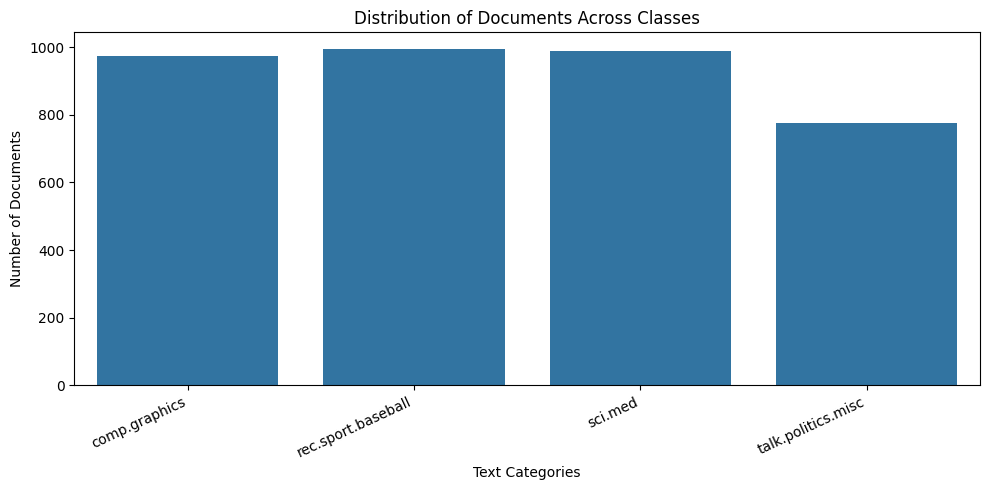


========== DATA SPLITTING ==========
Total documents: 3732
Training documents: 2985
Testing documents: 747
Training percentage: 80
Testing percentage: 20

========== TF-IDF INFORMATION ==========
Training matrix: (2985, 30000)
Testing matrix: (747, 30000)
Total extracted features: 30000
TF-IDF extraction completed!

========== MODEL TRAINING ==========

Training: Decision Tree
Accuracy: 0.6961
Precision: 0.7117
Recall: 0.6961
F1-Score: 0.6914
Macro F1-Score: 0.6888

Training: KNN
Accuracy: 0.8983
Precision: 0.9015
Recall: 0.8983
F1-Score: 0.8984
Macro F1-Score: 0.8979

Training: SVM
Accuracy: 0.909
Precision: 0.9117
Recall: 0.909
F1-Score: 0.9089
Macro F1-Score: 0.9078

Training: Naive Bayes
Accuracy: 0.9009
Precision: 0.9038
Recall: 0.9009
F1-Score: 0.9009
Macro F1-Score: 0.9004

All four classifiers trained successfully!

========== COMPARATIVE RESULTS ==========
   Classifier  Accuracy  Precision  Recall  F1-Score  Macro F1-Score
          SVM    0.9090     0.9117  0.9090    0.9089

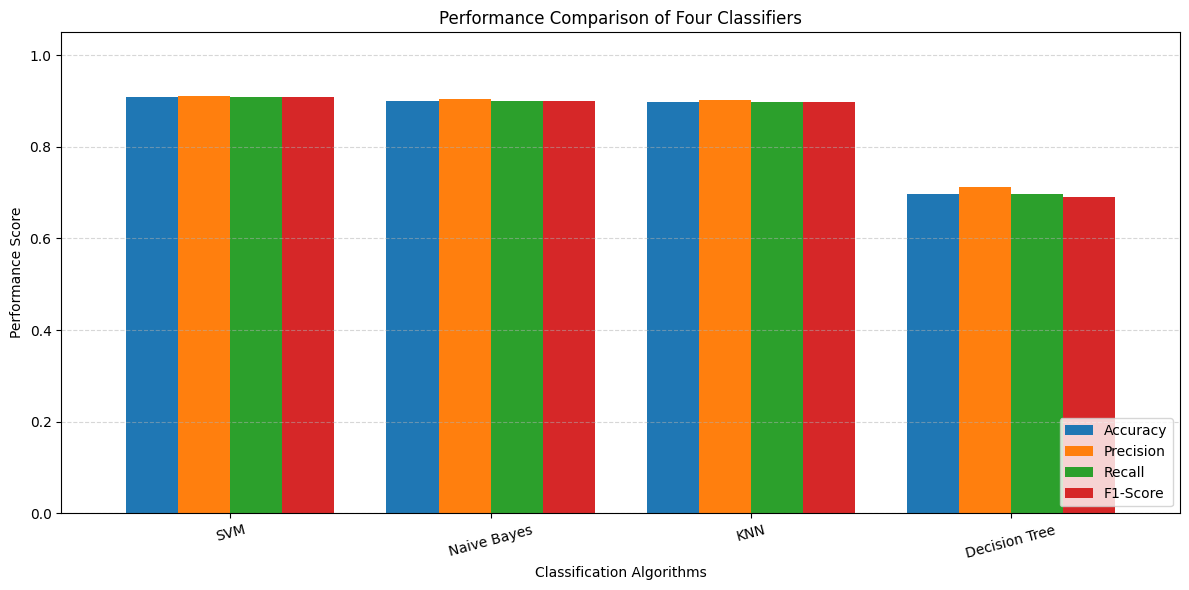

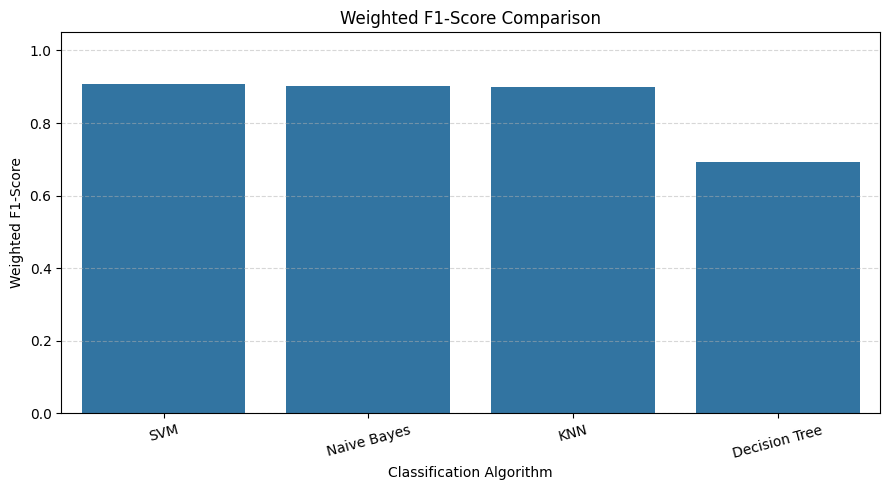

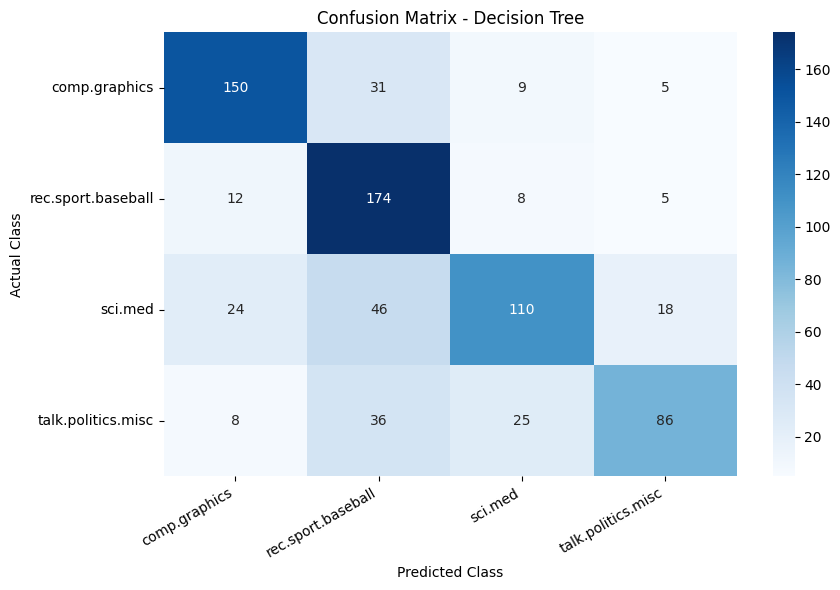


Confusion Matrix: Decision Tree
[[150  31   9   5]
 [ 12 174   8   5]
 [ 24  46 110  18]
 [  8  36  25  86]]


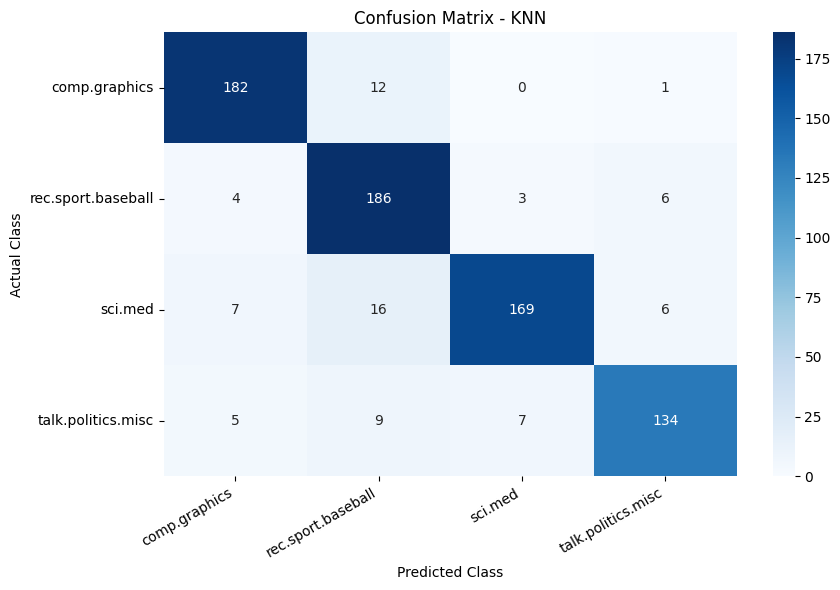


Confusion Matrix: KNN
[[182  12   0   1]
 [  4 186   3   6]
 [  7  16 169   6]
 [  5   9   7 134]]


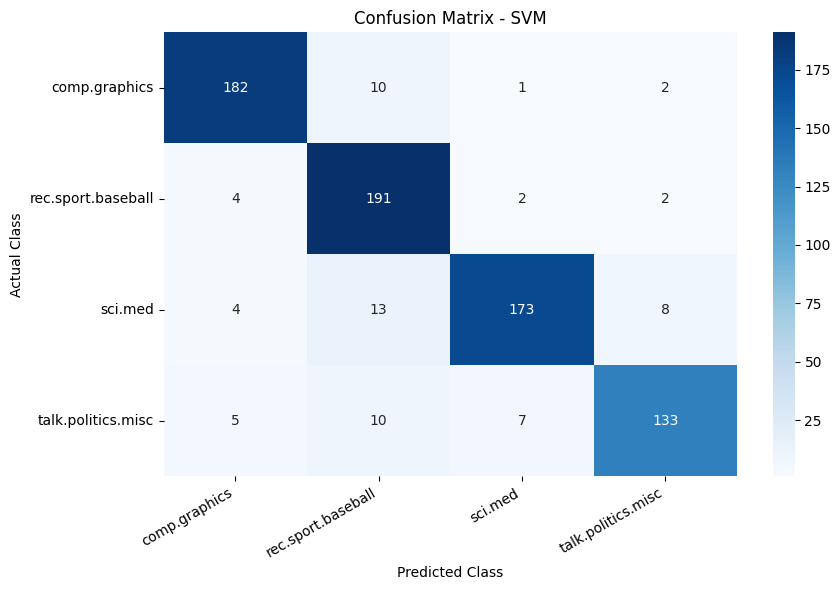


Confusion Matrix: SVM
[[182  10   1   2]
 [  4 191   2   2]
 [  4  13 173   8]
 [  5  10   7 133]]


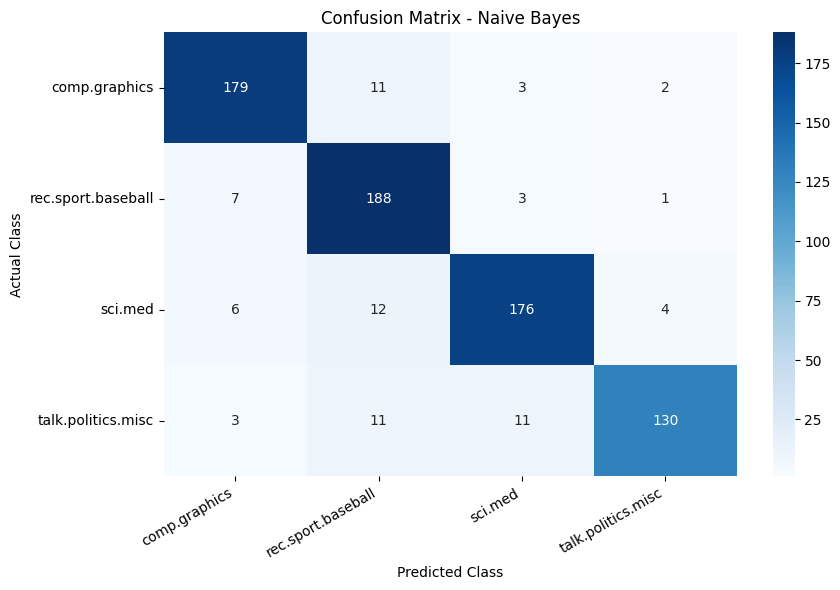


Confusion Matrix: Naive Bayes
[[179  11   3   2]
 [  7 188   3   1]
 [  6  12 176   4]
 [  3  11  11 130]]

CLASSIFICATION REPORT: Decision Tree
                    precision    recall  f1-score   support

     comp.graphics       0.77      0.77      0.77       195
rec.sport.baseball       0.61      0.87      0.72       199
           sci.med       0.72      0.56      0.63       198
talk.politics.misc       0.75      0.55      0.64       155

          accuracy                           0.70       747
         macro avg       0.71      0.69      0.69       747
      weighted avg       0.71      0.70      0.69       747


CLASSIFICATION REPORT: KNN
                    precision    recall  f1-score   support

     comp.graphics       0.92      0.93      0.93       195
rec.sport.baseball       0.83      0.93      0.88       199
           sci.med       0.94      0.85      0.90       198
talk.politics.misc       0.91      0.86      0.89       155

          accuracy                       

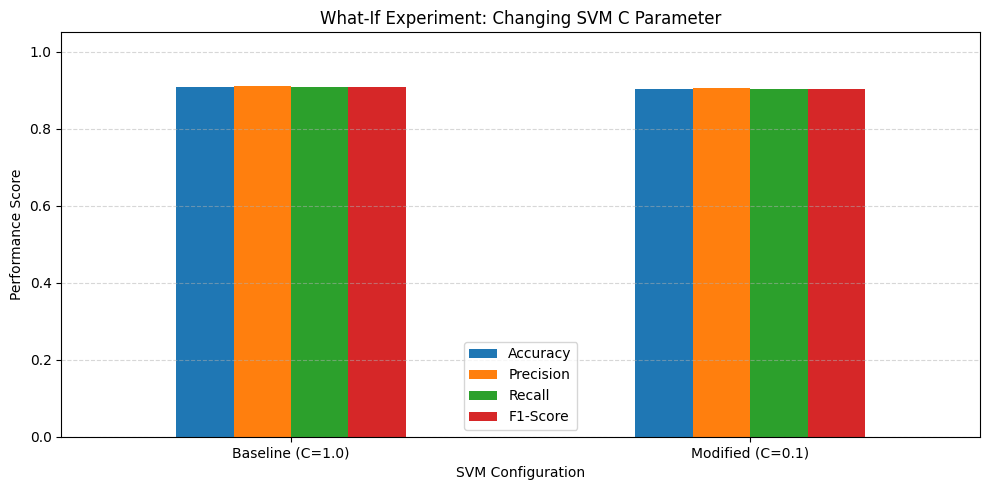


========== WHAT-IF INTERPRETATION ==========
Baseline SVM C = 1.0
Modified SVM C = 0.1
F1-score change: -0.0067
Accuracy change: -0.0067
Reducing C decreased the weighted F1-score.
The actual result should be discussed in terms of regularization and the trade-off between model complexity and training errors.

Models and TF-IDF vectorizer saved successfully!

FINAL PROJECT VERIFICATION
Four classifiers trained: YES
Same dataset used: YES
Same training/testing split: YES
Same TF-IDF representation: YES
Evaluation metrics calculated: YES
Comparative table generated: YES
Graphs saved: YES
Four confusion matrices saved: YES
What-if experiment performed: YES
Predictions saved: YES
Models saved: YES
Configuration saved: YES

All required result files verified!

Best classifier: SVM
Best weighted F1-score: 0.9089

ZIP file created: Text_Classification_Complete_Results.zip

Project execution completed!
Download the ZIP file from the Colab Files panel.


In [1]:

# =====================================================================
# TEXT CLASSIFICATION COMPARATIVE STUDY
#
# Decision Tree vs KNN vs SVM vs Naive Bayes
#
# Dataset: 20 Newsgroups
# Feature Extraction: TF-IDF
# Evaluation: Accuracy, Precision, Recall, F1-score
# What-if Experiment: SVM C parameter
# =====================================================================


# =====================================================================
# STEP 1: IMPORT LIBRARIES
# =====================================================================

import os
import zipfile
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.datasets import fetch_20newsgroups

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import LinearSVC

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

OUTPUT_FOLDER = "Text_Classification_Results"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("All libraries imported successfully!")


# =====================================================================
# STEP 2: LOAD DATASET
# =====================================================================

categories = [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.med",
    "talk.politics.misc"
]

dataset = fetch_20newsgroups(
    subset="all",
    categories=categories,
    shuffle=True,
    random_state=RANDOM_STATE,
    remove=("headers", "footers", "quotes")
)

X = np.array(dataset.data, dtype=object)

y = np.array(dataset.target)

class_names = dataset.target_names

print("\n========== DATASET INFORMATION ==========")

print("Dataset name: 20 Newsgroups")

print("Total documents:", len(X))

print("Number of classes:", len(class_names))

print("Classes:", class_names)

print("\nClass distribution:")

for i, name in enumerate(class_names):

    print(name, ":", np.sum(y == i))


# =====================================================================
# STEP 3: EXPLORE DATASET
# =====================================================================

class_distribution = pd.DataFrame({
    "Category": class_names,
    "Number of Documents": [
        np.sum(y == i) for i in range(len(class_names))
    ]
})

print("\nCLASS DISTRIBUTION TABLE")

print(class_distribution.to_string(index=False))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="Category",
    y="Number of Documents"
)

plt.title("Distribution of Documents Across Classes")

plt.xlabel("Text Categories")

plt.ylabel("Number of Documents")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_FOLDER, "dataset_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================================
# STEP 4: TRAIN-TEST SPLIT
# =====================================================================

# All four classifiers use exactly the same split.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\n========== DATA SPLITTING ==========")

print("Total documents:", len(X))

print("Training documents:", len(X_train))

print("Testing documents:", len(X_test))

print("Training percentage:", 80)

print("Testing percentage:", 20)


# =====================================================================
# STEP 5: TEXT FEATURE EXTRACTION USING TF-IDF
# =====================================================================

# Fit the vectorizer ONLY on training documents.
# Test documents are transformed using the same vectorizer.

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float64
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("\n========== TF-IDF INFORMATION ==========")

print("Training matrix:", X_train_tfidf.shape)

print("Testing matrix:", X_test_tfidf.shape)

print("Total extracted features:", len(tfidf.vocabulary_))

print("TF-IDF extraction completed!")


# =====================================================================
# STEP 6: DEFINE FOUR CLASSIFIERS
# =====================================================================

models = {

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=100,
        min_samples_split=2,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=RANDOM_STATE,
        max_iter=10000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}


# =====================================================================
# STEP 7: TRAIN ALL CLASSIFIERS AND CALCULATE METRICS
# =====================================================================

results = []

predictions = {}

trained_models = {}

print("\n========== MODEL TRAINING ==========")

for model_name, model in models.items():

    print("\nTraining:", model_name)

    # Train using the same TF-IDF features.

    model.fit(X_train_tfidf, y_train)

    # Predict test documents.

    y_pred = model.predict(X_test_tfidf)

    predictions[model_name] = y_pred

    trained_models[model_name] = model

    # Calculate metrics.

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    results.append({

        "Classifier": model_name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1-Score": f1,

        "Macro F1-Score": macro_f1

    })

    print("Accuracy:", round(accuracy, 4))

    print("Precision:", round(precision, 4))

    print("Recall:", round(recall, 4))

    print("F1-Score:", round(f1, 4))

    print("Macro F1-Score:", round(macro_f1, 4))

print("\nAll four classifiers trained successfully!")


# =====================================================================
# STEP 8: COMPARATIVE PERFORMANCE TABLE
# =====================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n========== COMPARATIVE RESULTS ==========")

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

results_df.to_csv(
    os.path.join(OUTPUT_FOLDER, "comparative_results.csv"),
    index=False
)


# =====================================================================
# STEP 9: GRAPH - COMPARISON OF ALL METRICS
# =====================================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

plot_data = results_df.set_index("Classifier")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Four Classifiers")

plt.xlabel("Classification Algorithms")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_FOLDER, "all_metrics_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================================
# STEP 10: GRAPH - F1 SCORE COMPARISON
# =====================================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Classifier",
    y="F1-Score"
)

plt.title("Weighted F1-Score Comparison")

plt.xlabel("Classification Algorithm")

plt.ylabel("Weighted F1-Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_FOLDER, "f1_score_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================================
# STEP 11: CONFUSION MATRIX ANALYSIS
# =====================================================================

confusion_matrices = {}

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    confusion_matrices[model_name] = cm

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title("Confusion Matrix - " + model_name)

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.xticks(rotation=30, ha="right")

    plt.yticks(rotation=0)

    plt.tight_layout()

    safe_name = model_name.replace(" ", "_")

    plt.savefig(
        os.path.join(
            OUTPUT_FOLDER,
            safe_name + "_confusion_matrix.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Save confusion matrix as CSV.

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    cm_df.to_csv(
        os.path.join(
            OUTPUT_FOLDER,
            safe_name + "_confusion_matrix.csv"
        )
    )

    print("\nConfusion Matrix:", model_name)

    print(cm)


# =====================================================================
# STEP 12: CLASSIFICATION REPORTS
# =====================================================================

reports = {}

for model_name, y_pred in predictions.items():

    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )

    reports[model_name] = report

    print("\n========================================")

    print("CLASSIFICATION REPORT:", model_name)

    print("========================================")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(class_names)),
            target_names=class_names,
            zero_division=0
        )
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        os.path.join(
            OUTPUT_FOLDER,
            model_name.replace(" ", "_") +
            "_classification_report.csv"
        )
    )


# =====================================================================
# STEP 13: IDENTIFY BEST CLASSIFIER
# =====================================================================

best_model_name = results_df.iloc[0]["Classifier"]

best_f1 = results_df.iloc[0]["F1-Score"]

best_accuracy = results_df.iloc[0]["Accuracy"]

print("\n========== BEST CLASSIFIER ==========")

print("Best classifier:", best_model_name)

print("Weighted F1-score:", round(best_f1, 4))

print("Accuracy:", round(best_accuracy, 4))

print(
    "The model with the highest weighted F1-score "
    "is selected as the best-performing classifier."
)


# =====================================================================
# STEP 14: WHAT-IF EXPERIMENT - CHANGE SVM PARAMETER C
# =====================================================================

# Baseline SVM: C = 1.0
# Modified SVM: C = 0.1
#
# Dataset, split and TF-IDF features remain unchanged.

print("\n========== WHAT-IF EXPERIMENT ==========")

baseline_svm = trained_models["SVM"]

baseline_predictions = predictions["SVM"]

modified_svm = LinearSVC(
    C=0.1,
    random_state=RANDOM_STATE,
    max_iter=10000
)

modified_svm.fit(
    X_train_tfidf,
    y_train
)

modified_predictions = modified_svm.predict(
    X_test_tfidf
)


# Calculate baseline metrics.

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_precision = precision_score(
    y_test,
    baseline_predictions,
    average="weighted",
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    average="weighted",
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="weighted",
    zero_division=0
)


# Calculate modified metrics.

modified_accuracy = accuracy_score(
    y_test,
    modified_predictions
)

modified_precision = precision_score(
    y_test,
    modified_predictions,
    average="weighted",
    zero_division=0
)

modified_recall = recall_score(
    y_test,
    modified_predictions,
    average="weighted",
    zero_division=0
)

modified_f1 = f1_score(
    y_test,
    modified_predictions,
    average="weighted",
    zero_division=0
)


what_if_df = pd.DataFrame({

    "SVM Configuration": [
        "Baseline (C=1.0)",
        "Modified (C=0.1)"
    ],

    "Accuracy": [
        baseline_accuracy,
        modified_accuracy
    ],

    "Precision": [
        baseline_precision,
        modified_precision
    ],

    "Recall": [
        baseline_recall,
        modified_recall
    ],

    "F1-Score": [
        baseline_f1,
        modified_f1
    ]

})

print("\nWHAT-IF EXPERIMENT RESULTS")

print(
    what_if_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

what_if_df.to_csv(
    os.path.join(OUTPUT_FOLDER, "what_if_results.csv"),
    index=False
)


# =====================================================================
# STEP 15: WHAT-IF EXPERIMENT GRAPH
# =====================================================================

what_if_plot = what_if_df.set_index(
    "SVM Configuration"
)[metrics]

what_if_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("What-If Experiment: Changing SVM C Parameter")

plt.xlabel("SVM Configuration")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_FOLDER, "what_if_experiment.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================================
# STEP 16: WHAT-IF EXPERIMENT INTERPRETATION
# =====================================================================

f1_difference = modified_f1 - baseline_f1

accuracy_difference = modified_accuracy - baseline_accuracy

print("\n========== WHAT-IF INTERPRETATION ==========")

print("Baseline SVM C = 1.0")

print("Modified SVM C = 0.1")

print("F1-score change:", round(f1_difference, 4))

print("Accuracy change:", round(accuracy_difference, 4))

if f1_difference > 0:

    print(
        "Reducing C improved the weighted F1-score."
    )

elif f1_difference < 0:

    print(
        "Reducing C decreased the weighted F1-score."
    )

else:

    print(
        "Reducing C did not change the weighted F1-score."
    )

print(
    "The actual result should be discussed in terms of "
    "regularization and the trade-off between model "
    "complexity and training errors."
)


# =====================================================================
# STEP 17: SAVE ALL TEST PREDICTIONS
# =====================================================================

prediction_df = pd.DataFrame({

    "Actual_Label": y_test,

    "Actual_Class": [
        class_names[i] for i in y_test
    ]

})

for model_name, y_pred in predictions.items():

    safe_name = model_name.replace(" ", "_")

    prediction_df[safe_name + "_Prediction"] = y_pred

    prediction_df[safe_name + "_Predicted_Class"] = [
        class_names[i] for i in y_pred
    ]


prediction_df.to_csv(
    os.path.join(OUTPUT_FOLDER, "test_predictions.csv"),
    index=False
)

# Save modified SVM predictions separately.

modified_prediction_df = pd.DataFrame({

    "Actual_Label": y_test,

    "Actual_Class": [
        class_names[i] for i in y_test
    ],

    "Modified_SVM_Prediction": modified_predictions,

    "Modified_SVM_Predicted_Class": [
        class_names[i] for i in modified_predictions
    ]

})

modified_prediction_df.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "modified_svm_predictions.csv"
    ),
    index=False
)


# =====================================================================
# STEP 18: SAVE TRAINED MODELS AND TF-IDF VECTORIZER
# =====================================================================

joblib.dump(
    tfidf,
    os.path.join(
        OUTPUT_FOLDER,
        "tfidf_vectorizer.joblib"
    )
)

for model_name, model in trained_models.items():

    safe_name = model_name.replace(" ", "_")

    joblib.dump(
        model,
        os.path.join(
            OUTPUT_FOLDER,
            safe_name + "_model.joblib"
        )
    )


joblib.dump(
    modified_svm,
    os.path.join(
        OUTPUT_FOLDER,
        "SVM_modified_C_0.1.joblib"
    )
)

print("\nModels and TF-IDF vectorizer saved successfully!")


# =====================================================================
# STEP 19: SAVE EXPERIMENT CONFIGURATION
# =====================================================================

configuration = f"""
TEXT CLASSIFICATION COMPARATIVE STUDY
=====================================

Dataset: 20 Newsgroups

Classes:
{class_names}

Total Documents: {len(X)}

Training Documents: {len(X_train)}

Testing Documents: {len(X_test)}

Train-Test Ratio: 80:20

Random State: {RANDOM_STATE}

FEATURE EXTRACTION
------------------
Method: TF-IDF
Lowercase: True
Stop Words: English
N-Gram Range: (1, 2)
Maximum Features: 30000
Minimum Document Frequency: 2
Maximum Document Frequency: 0.95

CLASSIFIERS
-----------
1. Decision Tree
2. K-Nearest Neighbours
3. Linear Support Vector Machine
4. Multinomial Naive Bayes

EVALUATION METRICS
------------------
Accuracy
Weighted Precision
Weighted Recall
Weighted F1-Score
Macro F1-Score

WHAT-IF EXPERIMENT
------------------
Baseline SVM C = 1.0
Modified SVM C = 0.1

RESULTS
-------
Best Classifier: {best_model_name}
Best Accuracy: {best_accuracy:.4f}
Best Weighted F1: {best_f1:.4f}

SVM Baseline F1: {baseline_f1:.4f}
SVM Modified F1: {modified_f1:.4f}

Execution Date:
{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

"""

with open(
    os.path.join(
        OUTPUT_FOLDER,
        "experiment_configuration.txt"
    ),
    "w",
    encoding="utf-8"
) as file:

    file.write(configuration)


# =====================================================================
# STEP 20: CREATE FINAL SUBMISSION ZIP
# =====================================================================

zip_filename = "Text_Classification_Complete_Results.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk(OUTPUT_FOLDER):

        for file_name in files:

            full_path = os.path.join(root, file_name)

            archive_path = os.path.relpath(
                full_path,
                OUTPUT_FOLDER
            )

            zip_file.write(
                full_path,
                archive_path
            )


# =====================================================================
# STEP 21: FINAL VERIFICATION
# =====================================================================

required_files = [

    "comparative_results.csv",

    "what_if_results.csv",

    "test_predictions.csv",

    "modified_svm_predictions.csv",

    "experiment_configuration.txt",

    "dataset_distribution.png",

    "all_metrics_comparison.png",

    "f1_score_comparison.png",

    "what_if_experiment.png",

    "tfidf_vectorizer.joblib"

]

for model_name in models:

    safe_name = model_name.replace(" ", "_")

    required_files.append(
        safe_name + "_confusion_matrix.png"
    )

    required_files.append(
        safe_name + "_confusion_matrix.csv"
    )

    required_files.append(
        safe_name + "_model.joblib"
    )

missing_files = [

    filename for filename in required_files

    if not os.path.exists(
        os.path.join(OUTPUT_FOLDER, filename)
    )

]

print("\n" + "=" * 60)

print("FINAL PROJECT VERIFICATION")

print("=" * 60)

print("Four classifiers trained: YES")

print("Same dataset used: YES")

print("Same training/testing split: YES")

print("Same TF-IDF representation: YES")

print("Evaluation metrics calculated: YES")

print("Comparative table generated: YES")

print("Graphs saved: YES")

print("Four confusion matrices saved: YES")

print("What-if experiment performed: YES")

print("Predictions saved: YES")

print("Models saved: YES")

print("Configuration saved: YES")

if len(missing_files) == 0:

    print("\nAll required result files verified!")

else:

    print("\nMissing files:", missing_files)

print("\nBest classifier:", best_model_name)

print("Best weighted F1-score:", round(best_f1, 4))

print("\nZIP file created:", zip_filename)

print("\nProject execution completed!")

print("Download the ZIP file from the Colab Files panel.")

# =====================================================================
# END OF PROJECT
# =====================================================================
